In [1]:
# ============================================================
# Dissertation Chapter 3.4
# Co-funding Network Analysis (BC)
#
# Dataset:
# BC_data_cleaned_with_OND.csv
#
# Research Questions:
# RQ1. Central funders
# RQ2. Funder communities
# RQ3. Temporal evolution
# ============================================================

0. Install

In [2]:
# ============================================================
# Package Installation
# ============================================================

import sys

!{sys.executable} -m pip install networkx python-louvain

You should consider upgrading via the 'c:\users\jkimi\appdata\local\programs\python\python37\python.exe -m pip install --upgrade pip' command.


1. Create co-funding edge list

In [3]:
# ============================================================
# Step 1:
# Create co-funding edge list from Funding_Details_OND
# ============================================================

import pandas as pd
import ast
from itertools import combinations
from collections import Counter

# ------------------------------------------------------------
# Load BC dataset
# ------------------------------------------------------------

df = pd.read_csv("BC_data_cleaned_with_OND.csv")

# ------------------------------------------------------------
# Function:
# Convert Funding_Details_OND into a list of funders
# ------------------------------------------------------------

def parse_funders(x):

    if pd.isna(x):
        return []

    x = str(x).strip()

    if x in ["", "[]", "nan", "None", "NaN"]:
        return []

    try:
        funders = ast.literal_eval(x)

        if isinstance(funders, list):
            return [
                str(f).strip()
                for f in funders
                if str(f).strip()
            ]

    except:
        pass

    return [
        f.strip()
        for f in x.split(";")
        if f.strip()
    ]

# ------------------------------------------------------------
# Create funder list and funder count
# ------------------------------------------------------------

df["Funder_List"] = df["Funding_Details_OND"].apply(parse_funders)

df["Funder_Count"] = df["Funder_List"].apply(len)

# ------------------------------------------------------------
# Keep only co-funded papers
#
# Co-funded paper:
# A paper with two or more funders
# ------------------------------------------------------------

cofunded_df = df[
    df["Funder_Count"] >= 2
].copy()

print("Total papers:", len(df))
print("Co-funded papers:", len(cofunded_df))

# ------------------------------------------------------------
# Create co-funding pairs
#
# Example:
# ['NSF', 'NIH', 'DOE']
#
# becomes:
# ('DOE', 'NIH')
# ('DOE', 'NSF')
# ('NIH', 'NSF')
# ------------------------------------------------------------

edge_records = []

for _, row in cofunded_df.iterrows():

    paper_id = row["Paper_id"]
    year = row["Year"]
    source_title = row["Source title"]
    funders = row["Funder_List"]

    # Remove duplicated funders within the same paper
    funders = sorted(set(funders))

    # Create all unordered funder pairs
    for funder_a, funder_b in combinations(funders, 2):

        edge_records.append({
            "Paper_id": paper_id,
            "Year": year,
            "Source title": source_title,
            "Funder_A": funder_a,
            "Funder_B": funder_b
        })

# ------------------------------------------------------------
# Paper-level edge list
#
# Each row represents one co-funding relationship
# observed in one paper.
# ------------------------------------------------------------

paper_edge_list = pd.DataFrame(edge_records)

print("Paper-level co-funding edges:", len(paper_edge_list))

paper_edge_list.head()

Total papers: 72714
Co-funded papers: 34621
Paper-level co-funding edges: 249245


,Paper_id,Year,Source title,Funder_A,Funder_B
0,10000002,2020,WILDLIFE SOCIETY BULLETIN,Fish and Wildlife Service,Geological Survey
1,10000006,2020,CONSERVATION SCIENCE AND PRACTICE,Elephant Cooperation Foundation,European Commission
2,10000006,2020,CONSERVATION SCIENCE AND PRACTICE,Elephant Cooperation Foundation,High Water Global Foundation
3,10000006,2020,CONSERVATION SCIENCE AND PRACTICE,Elephant Cooperation Foundation,Lundin Norway
4,10000006,2020,CONSERVATION SCIENCE AND PRACTICE,Elephant Cooperation Foundation,Mulago Foundation


2. Create weighted co-funding edge list

In [4]:
# ============================================================
# Step 2:
# Create weighted co-funding edge list
# Compatible with older pandas versions
# ============================================================

weighted_edge_list = (
    paper_edge_list
    .groupby(["Funder_A", "Funder_B"])
    .agg({
        "Paper_id": "count",
        "Year": ["min", "max"]
    })
    .reset_index()
)

# Rename columns
weighted_edge_list.columns = [
    "Funder_A",
    "Funder_B",
    "Weight",
    "First_Year",
    "Last_Year"
]

# Sort by edge weight
weighted_edge_list = weighted_edge_list.sort_values(
    "Weight",
    ascending=False
)

weighted_edge_list.head(20)

,Funder_A,Funder_B,Weight,First_Year,Last_Year
61787,Conselho Nacional de Desenvolvimento Cientific...,Coordenacao de Aperfeicoamento de Pessoal de N...,674,2009,2020
62085,Conselho Nacional de Desenvolvimento Cientific...,Fundacao de Amparo a Pesquisa do Estado de Sao...,269,2009,2020
80330,Direct For Biological Sciences,National Science Foundation,224,2009,2020
166874,Natural Environment Research Council,Research & Innovation Natural Environment Rese...,190,2009,2020
82129,Division Of Environmental Biology,National Science Foundation,173,2009,2020
62043,Conselho Nacional de Desenvolvimento Cientific...,Fundacao Carlos Chagas Filho de Amparo a Pesqu...,140,2009,2020
115136,Fundamental Research Funds for the Central Uni...,National Natural Science Foundation of China,138,2010,2020
65631,Coordenacao de Aperfeicoamento de Pessoal de N...,Fundacao de Amparo a Pesquisa do Estado de Sao...,137,2009,2020
53557,Chinese Academy of Sciences,National Natural Science Foundation of China,131,2009,2020
159896,National Key Research and Development Program ...,National Natural Science Foundation of China,129,2017,2020


In [5]:
# ============================================================
# Summary statistics
# ============================================================

print("Number of co-funded papers:", len(cofunded_df))

print("Number of paper-level co-funding edges:", len(paper_edge_list))

print("Number of unique funder pairs:", len(weighted_edge_list))

print("Number of unique funders in co-funding network:")

unique_funders = set(weighted_edge_list["Funder_A"]).union(
    set(weighted_edge_list["Funder_B"])
)

print(len(unique_funders))

Number of co-funded papers: 34621
Number of paper-level co-funding edges: 249245
Number of unique funder pairs: 193884
Number of unique funders in co-funding network:
34191


In [6]:
# ------------------------------------------------------------
# Save edge lists
# ------------------------------------------------------------

paper_edge_list.to_csv(
    "paper_level_cofunding_edge_list_BC.csv",
    index=False
)

weighted_edge_list.to_csv(
    "weighted_cofunding_edge_list_BC.csv",
    index=False
)

3. Build Whole-period Network

In [7]:
# ============================================================
# Step 3
# Build Whole-period Co-funding Network
# Period: 2009–2020
# ============================================================

import networkx as nx

print(nx.__version__)

# ------------------------------------------------------------
# Create an undirected weighted graph
# ------------------------------------------------------------

G = nx.Graph()

# ------------------------------------------------------------
# Add weighted edges
#
# Node:
#   Funder
#
# Edge:
#   Co-funding relationship between two funders
#
# Weight:
#   Number of papers co-funded by the two funders
# ------------------------------------------------------------

for _, row in weighted_edge_list.iterrows():

    G.add_edge(
        row["Funder_A"],
        row["Funder_B"],
        weight=row["Weight"],
        first_year=row["First_Year"],
        last_year=row["Last_Year"]
    )

# ------------------------------------------------------------
# Basic network summary
# ------------------------------------------------------------

num_nodes = G.number_of_nodes()
num_edges = G.number_of_edges()
density = nx.density(G)

print("Whole-period BC Co-funding Network")
print("-----------------------------------")
print(f"Number of nodes: {num_nodes}")
print(f"Number of edges: {num_edges}")
print(f"Network density: {density:.6f}")

2.6.3
Whole-period BC Co-funding Network
-----------------------------------
Number of nodes: 34191
Number of edges: 193884
Network density: 0.000332


In [8]:
# ============================================================
# Connected Components
# ============================================================

components = list(nx.connected_components(G))

num_components = len(components)

largest_component = max(
    components,
    key=len
)

largest_component_size = len(largest_component)

print("Connected Components")
print("--------------------")
print(f"Number of connected components: {num_components}")
print(f"Largest component size: {largest_component_size}")
print(
    f"Largest component share: "
    f"{largest_component_size / num_nodes * 100:.2f}%"
)

Connected Components
--------------------
Number of connected components: 649
Largest component size: 32676
Largest component share: 95.57%


In [9]:
# ============================================================
# Whole-period Network-level Metrics
# ============================================================

# Average degree
avg_degree = sum(dict(G.degree()).values()) / num_nodes

# Average weighted degree
avg_weighted_degree = sum(
    dict(G.degree(weight="weight")).values()
) / num_nodes

# Clustering coefficient
avg_clustering = nx.average_clustering(G)

# Weighted clustering coefficient
avg_weighted_clustering = nx.average_clustering(
    G,
    weight="weight"
)

print("Network-level Metrics")
print("---------------------")
print(f"Average degree: {avg_degree:.3f}")
print(f"Average weighted degree: {avg_weighted_degree:.3f}")
print(f"Average clustering coefficient: {avg_clustering:.3f}")
print(f"Average weighted clustering coefficient: {avg_weighted_clustering:.3f}")

Network-level Metrics
---------------------
Average degree: 11.341
Average weighted degree: 14.580
Average clustering coefficient: 0.630
Average weighted clustering coefficient: 0.001


In [10]:
# ============================================================
# Average Path Length
# Calculated only for the largest connected component
# ============================================================

G_lcc = G.subgraph(largest_component).copy()

if G_lcc.number_of_nodes() > 1:
    avg_path_length = nx.average_shortest_path_length(G_lcc)
    diameter = nx.diameter(G_lcc)

    print("Largest Connected Component Metrics")
    print("-----------------------------------")
    print(f"Average path length: {avg_path_length:.3f}")
    print(f"Diameter: {diameter}")
else:
    print("Largest connected component has fewer than 2 nodes.")

KeyboardInterrupt: 

In [11]:
# ============================================================
# Table 3.X
# Whole-period Co-funding Network Summary
# ============================================================

whole_network_summary = pd.DataFrame({
    "Network": ["BC co-funding network"],
    "Period": ["2009-2020"],
    "Nodes": [num_nodes],
    "Edges": [num_edges],
    "Density": [density],
    "Connected Components": [num_components],
    "Largest Component Size": [largest_component_size],
    "Largest Component Share (%)": [
        largest_component_size / num_nodes * 100
    ],
    "Average Degree": [avg_degree],
    "Average Weighted Degree": [avg_weighted_degree],
    "Average Clustering": [avg_clustering],
    "Average Weighted Clustering": [avg_weighted_clustering]
})

whole_network_summary = whole_network_summary.round(4)

whole_network_summary

,Network,Period,Nodes,Edges,Density,Connected Components,Largest Component Size,Largest Component Share (%),Average Degree,Average Weighted Degree,Average Clustering,Average Weighted Clustering
0,BC co-funding network,2009-2020,34191,193884,0.0003,649,32676,95.569,11.3412,14.5796,0.6299,0.0012


In [12]:
whole_network_summary.to_csv(
    "Table_Whole_Period_Cofunding_Network_Summary_BC.csv",
    index=False
)

4. Centrality Analysis

In [13]:
# ============================================================
# Step 4
# Centrality Analysis
# Whole-period BC Co-funding Network, 2009–2020
# ============================================================

import pandas as pd
import networkx as nx

# ------------------------------------------------------------
# Degree
# Number of unique co-funding partners
# ------------------------------------------------------------

degree_dict = dict(G.degree())

# ------------------------------------------------------------
# Weighted degree
# Sum of edge weights connected to each funder
# ------------------------------------------------------------

weighted_degree_dict = dict(
    G.degree(weight="weight")
)

# ------------------------------------------------------------
# Degree centrality
# Normalized degree centrality
# ------------------------------------------------------------

degree_centrality_dict = nx.degree_centrality(G)

# ------------------------------------------------------------
# Betweenness centrality
#
# For weighted networks, distance should be inverse of weight:
# stronger co-funding relationship = shorter distance
# ------------------------------------------------------------

for u, v, data in G.edges(data=True):
    data["distance"] = 1 / data["weight"]

# Use approximate betweenness centrality
betweenness_dict = nx.betweenness_centrality(
    G,
    k=500,
    weight="distance",
    normalized=True,
    seed=42
)

# ------------------------------------------------------------
# Create centrality table
# ------------------------------------------------------------

centrality_df = pd.DataFrame({
    "Funder": list(G.nodes()),
    "Degree": [degree_dict[n] for n in G.nodes()],
    "Weighted Degree": [weighted_degree_dict[n] for n in G.nodes()],
    "Degree Centrality": [degree_centrality_dict[n] for n in G.nodes()],
    "Betweenness Centrality": [betweenness_dict[n] for n in G.nodes()]
})

centrality_df = centrality_df.sort_values(
    "Weighted Degree",
    ascending=False
)

centrality_df.head(20)

,Funder,Degree,Weighted Degree,Degree Centrality,Betweenness Centrality
4,National Science Foundation,4639,9175,0.135683,0.733529
10,National Natural Science Foundation of China,2549,5301,0.074554,0.182021
21,Natural Sciences and Engineering Research Coun...,2039,4708,0.059637,0.129388
0,Conselho Nacional de Desenvolvimento Cientific...,1591,4365,0.046534,0.111575
5,Natural Environment Research Council,1987,4178,0.058116,0.327522
1,Coordenacao de Aperfeicoamento de Pessoal de N...,1019,2634,0.029804,0.017642
25,European Commission,1687,2617,0.049342,0.161078
14,Fish and Wildlife Service,1396,2530,0.040831,0.113346
52,Australian Research Council,1333,2407,0.038988,0.104717
48,Rufford Foundation,1125,1945,0.032904,0.056844


In [14]:
# ============================================================
# Table 3.X
# Top 20 Funders by Degree
# ============================================================

top20_degree = (
    centrality_df
    .sort_values("Degree", ascending=False)
    .head(20)
    .copy()
)

top20_degree

,Funder,Degree,Weighted Degree,Degree Centrality,Betweenness Centrality
4,National Science Foundation,4639,9175,0.135683,0.733529
10,National Natural Science Foundation of China,2549,5301,0.074554,0.182021
21,Natural Sciences and Engineering Research Coun...,2039,4708,0.059637,0.129388
5,Natural Environment Research Council,1987,4178,0.058116,0.327522
25,European Commission,1687,2617,0.049342,0.161078
0,Conselho Nacional de Desenvolvimento Cientific...,1591,4365,0.046534,0.111575
14,Fish and Wildlife Service,1396,2530,0.040831,0.113346
52,Australian Research Council,1333,2407,0.038988,0.104717
48,Rufford Foundation,1125,1945,0.032904,0.056844
1,Coordenacao de Aperfeicoamento de Pessoal de N...,1019,2634,0.029804,0.017642


In [15]:
# ============================================================
# Table 3.X
# Top 20 Funders by Weighted Degree
# ============================================================

top20_weighted_degree = (
    centrality_df
    .sort_values("Weighted Degree", ascending=False)
    .head(20)
    .copy()
)

top20_weighted_degree

,Funder,Degree,Weighted Degree,Degree Centrality,Betweenness Centrality
4,National Science Foundation,4639,9175,0.135683,0.733529
10,National Natural Science Foundation of China,2549,5301,0.074554,0.182021
21,Natural Sciences and Engineering Research Coun...,2039,4708,0.059637,0.129388
0,Conselho Nacional de Desenvolvimento Cientific...,1591,4365,0.046534,0.111575
5,Natural Environment Research Council,1987,4178,0.058116,0.327522
1,Coordenacao de Aperfeicoamento de Pessoal de N...,1019,2634,0.029804,0.017642
25,European Commission,1687,2617,0.049342,0.161078
14,Fish and Wildlife Service,1396,2530,0.040831,0.113346
52,Australian Research Council,1333,2407,0.038988,0.104717
48,Rufford Foundation,1125,1945,0.032904,0.056844


In [16]:
# ============================================================
# Table 3.X
# Top 20 Funders by Betweenness Centrality
# ============================================================

top20_betweenness = (
    centrality_df
    .sort_values("Betweenness Centrality", ascending=False)
    .head(20)
    .copy()
)

top20_betweenness

,Funder,Degree,Weighted Degree,Degree Centrality,Betweenness Centrality
4,National Science Foundation,4639,9175,0.135683,0.733529
5,Natural Environment Research Council,1987,4178,0.058116,0.327522
10,National Natural Science Foundation of China,2549,5301,0.074554,0.182021
25,European Commission,1687,2617,0.049342,0.161078
21,Natural Sciences and Engineering Research Coun...,2039,4708,0.059637,0.129388
14,Fish and Wildlife Service,1396,2530,0.040831,0.113346
0,Conselho Nacional de Desenvolvimento Cientific...,1591,4365,0.046534,0.111575
52,Australian Research Council,1333,2407,0.038988,0.104717
48,Rufford Foundation,1125,1945,0.032904,0.056844
22,National Geographic Society,905,1353,0.026470,0.031210


In [17]:
# ============================================================
# Save centrality results
# ============================================================

centrality_df.to_csv(
    "centrality_results_BC_whole_period.csv",
    index=False
)

top20_degree.to_csv(
    "top20_funders_by_degree_BC.csv",
    index=False
)

top20_weighted_degree.to_csv(
    "top20_funders_by_weighted_degree_BC.csv",
    index=False
)

top20_betweenness.to_csv(
    "top20_funders_by_betweenness_BC.csv",
    index=False
)

5. Louvain community detection

In [18]:
# ============================================================
# Step 5
# Louvain Community Detection
# ============================================================

import community as community_louvain

partition = community_louvain.best_partition(
    G,
    weight="weight",
    random_state=42
)

# Add community information to centrality table
centrality_df["Community"] = centrality_df["Funder"].map(partition)

centrality_df.head()

,Funder,Degree,Weighted Degree,Degree Centrality,Betweenness Centrality,Community
4,National Science Foundation,4639,9175,0.135683,0.733529,1
10,National Natural Science Foundation of China,2549,5301,0.074554,0.182021,3
21,Natural Sciences and Engineering Research Coun...,2039,4708,0.059637,0.129388,5
0,Conselho Nacional de Desenvolvimento Cientific...,1591,4365,0.046534,0.111575,0
5,Natural Environment Research Council,1987,4178,0.058116,0.327522,2


In [19]:
# ============================================================
# Community Summary
# ============================================================

community_summary = (
    centrality_df
    .groupby("Community")
    .agg(
        Number_of_Funders=("Funder", "count"),
        Avg_Degree=("Degree", "mean"),
        Avg_Weighted_Degree=("Weighted Degree", "mean"),
        Avg_Betweenness=("Betweenness Centrality", "mean")
    )
    .reset_index()
    .sort_values("Number_of_Funders", ascending=False)
)

community_summary = community_summary.round(4)

community_summary

,Community,Number_of_Funders,Avg_Degree,Avg_Weighted_Degree,Avg_Betweenness
1,1,4754,12.3727,15.6931,0.0002
3,3,3347,7.6878,10.3197,0.0001
2,2,2850,13.8565,18.4646,0.0002
4,4,2850,11.7905,15.0172,0.0001
6,6,2845,11.8404,13.8882,0.0001
...,...,...,...,...,...
306,306,2,1.0000,1.0000,0.0000
304,304,2,1.0000,1.0000,0.0000
303,303,2,1.0000,1.0000,0.0000
302,302,2,1.0000,1.0000,0.0000


In [20]:
# ============================================================
# Community Summary Table
# ============================================================

# Top funders within each community by weighted degree
def get_top_funders(group, n=5):
    return "; ".join(
        group
        .sort_values("Weighted Degree", ascending=False)
        ["Funder"]
        .head(n)
    )

community_summary_table = (
    centrality_df
    .groupby("Community")
    .apply(
        lambda g: pd.Series({
            "Number of Funders": len(g),
            "Top Funders": get_top_funders(g, n=5),
            "Average Degree": g["Degree"].mean(),
            "Average Weighted Degree": g["Weighted Degree"].mean(),
            "Average Betweenness": g["Betweenness Centrality"].mean(),
            "Max Weighted Degree": g["Weighted Degree"].max(),
            "Most Central Funder": (
                g.sort_values("Weighted Degree", ascending=False)
                 ["Funder"]
                 .iloc[0]
            )
        })
    )
    .reset_index()
)

community_summary_table = community_summary_table.sort_values(
    "Number of Funders",
    ascending=False
)

community_summary_table[
    [
        "Average Degree",
        "Average Weighted Degree",
        "Average Betweenness"
    ]
] = community_summary_table[
    [
        "Average Degree",
        "Average Weighted Degree",
        "Average Betweenness"
    ]
].round(4)

community_summary_table

,Community,Number of Funders,Top Funders,Average Degree,Average Weighted Degree,Average Betweenness,Max Weighted Degree,Most Central Funder
1,1,4754,National Science Foundation; National Geograph...,12.3727,15.6931,0.0002,9175,National Science Foundation
3,3,3347,National Natural Science Foundation of China; ...,7.6878,10.3197,0.0001,5301,National Natural Science Foundation of China
2,2,2850,Natural Environment Research Council; Research...,13.8565,18.4646,0.0002,4178,Natural Environment Research Council
4,4,2850,Fish and Wildlife Service; Geological Survey; ...,11.7905,15.0172,0.0001,2530,Fish and Wildlife Service
6,6,2845,European Commission; Portuguese Foundation for...,11.8404,13.8882,0.0001,2617,European Commission
...,...,...,...,...,...,...,...,...
306,306,2,PLATPROT project; Polish National Center for R...,1.0000,1.0000,0.0000,1,PLATPROT project
304,304,2,PECASE award; RMRS,1.0000,1.0000,0.0000,1,PECASE award
303,303,2,North Carolina Space Grant; University of Nort...,1.0000,1.0000,0.0000,1,North Carolina Space Grant
302,302,2,North Carolina Native Plant Society; Society o...,1.0000,1.0000,0.0000,1,North Carolina Native Plant Society


In [21]:
community_summary_table.to_csv(
    "Table_Community_Summary_BC.csv",
    index=False
)

In [22]:
table_major_communities = (
    community_summary_table
    .head(10)
    .copy()
)

table_major_communities

,Community,Number of Funders,Top Funders,Average Degree,Average Weighted Degree,Average Betweenness,Max Weighted Degree,Most Central Funder
1,1,4754,National Science Foundation; National Geograph...,12.3727,15.6931,0.0002,9175,National Science Foundation
3,3,3347,National Natural Science Foundation of China; ...,7.6878,10.3197,0.0001,5301,National Natural Science Foundation of China
2,2,2850,Natural Environment Research Council; Research...,13.8565,18.4646,0.0002,4178,Natural Environment Research Council
4,4,2850,Fish and Wildlife Service; Geological Survey; ...,11.7905,15.0172,0.0001,2530,Fish and Wildlife Service
6,6,2845,European Commission; Portuguese Foundation for...,11.8404,13.8882,0.0001,2617,European Commission
8,8,2654,Rufford Foundation; Wildlife Conservation Soci...,15.0821,19.1002,0.0001,1945,Rufford Foundation
10,10,2206,Swiss National Science Foundation; National Re...,11.9660,14.4139,0.0001,800,Swiss National Science Foundation
5,5,2166,Natural Sciences and Engineering Research Coun...,18.0060,26.0886,0.0001,4708,Natural Sciences and Engineering Research Coun...
0,0,1866,Conselho Nacional de Desenvolvimento Cientific...,10.6951,15.5638,0.0001,4365,Conselho Nacional de Desenvolvimento Cientific...
9,9,1854,Australian Research Council; Australian Resear...,10.9547,13.9347,0.0001,2407,Australian Research Council


In [23]:
table_major_communities.to_csv(
    "Table_Major_Communities_BC.csv",
    index=False
)

6. Visualization

Visualization network
---------------------
Nodes: 1282
Edges: 2754


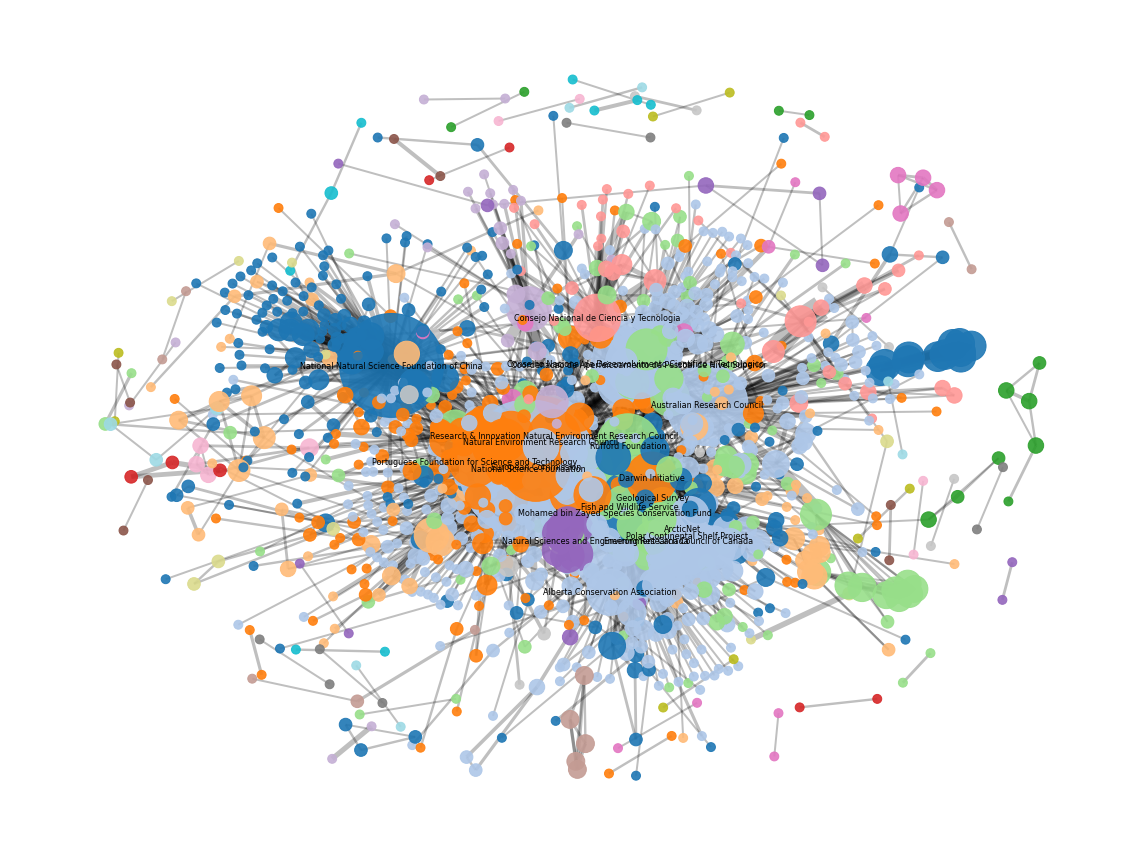

In [24]:
# ============================================================
# Figure 3.8
# Whole-period BC Co-funding Network, 2009–2020
#
# Node size = degree
# Edge width = co-funding frequency
# Node color = Louvain community
# ============================================================

import matplotlib.pyplot as plt
import networkx as nx

# ------------------------------------------------------------
# Filter graph for visualization
#
# Keep edges with weight >= 2
# This improves readability.
# ------------------------------------------------------------

min_edge_weight = 5

edges_to_keep = [
    (u, v)
    for u, v, d in G.edges(data=True)
    if d["weight"] >= min_edge_weight
]

G_vis = G.edge_subgraph(edges_to_keep).copy()

print("Visualization network")
print("---------------------")
print("Nodes:", G_vis.number_of_nodes())
print("Edges:", G_vis.number_of_edges())

# ------------------------------------------------------------
# Louvain communities for visualization graph
# ------------------------------------------------------------

partition_vis = community_louvain.best_partition(
    G_vis,
    weight="weight",
    random_state=42
)

# ------------------------------------------------------------
# Node size = degree
# ------------------------------------------------------------

degree_vis = dict(G_vis.degree())

node_sizes = [
    degree_vis[n] * 80
    for n in G_vis.nodes()
]

# ------------------------------------------------------------
# Node color = community
# ------------------------------------------------------------

node_colors = [
    partition_vis[n]
    for n in G_vis.nodes()
]

# ------------------------------------------------------------
# Edge width = edge weight
# ------------------------------------------------------------

edge_widths = [
    G_vis[u][v]["weight"] * 0.4
    for u, v in G_vis.edges()
]

# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------

pos = nx.spring_layout(
    G_vis,
    weight="weight",
    seed=42,
    k=0.25
)

# ------------------------------------------------------------
# Draw network
# ------------------------------------------------------------

plt.figure(figsize=(16, 12))

nx.draw_networkx_edges(
    G_vis,
    pos,
    width=edge_widths,
    alpha=0.25
)

nx.draw_networkx_nodes(
    G_vis,
    pos,
    node_size=node_sizes,
    node_color=node_colors,
    cmap=plt.cm.tab20,
    alpha=0.9
)

# ------------------------------------------------------------
# Label only top funders by degree
# ------------------------------------------------------------

top_label_nodes = (
    pd.Series(degree_vis)
    .sort_values(ascending=False)
    .head(20)
    .index
)

labels = {
    node: node
    for node in top_label_nodes
}

nx.draw_networkx_labels(
    G_vis,
    pos,
    labels=labels,
    font_size=8
)

# plt.title(
#     "Figure 3.8. Whole-period BC Co-funding Network, 2009–2020"
# )

plt.axis("off")
plt.tight_layout()

plt.savefig(
    "Figure_3_8_Whole_Period_Cofunding_Network_BC.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_3_8_Whole_Period_Cofunding_Network_BC.pdf",
    bbox_inches="tight"
)

plt.show()

Top funders network
-------------------
Nodes: 100
Edges: 1721


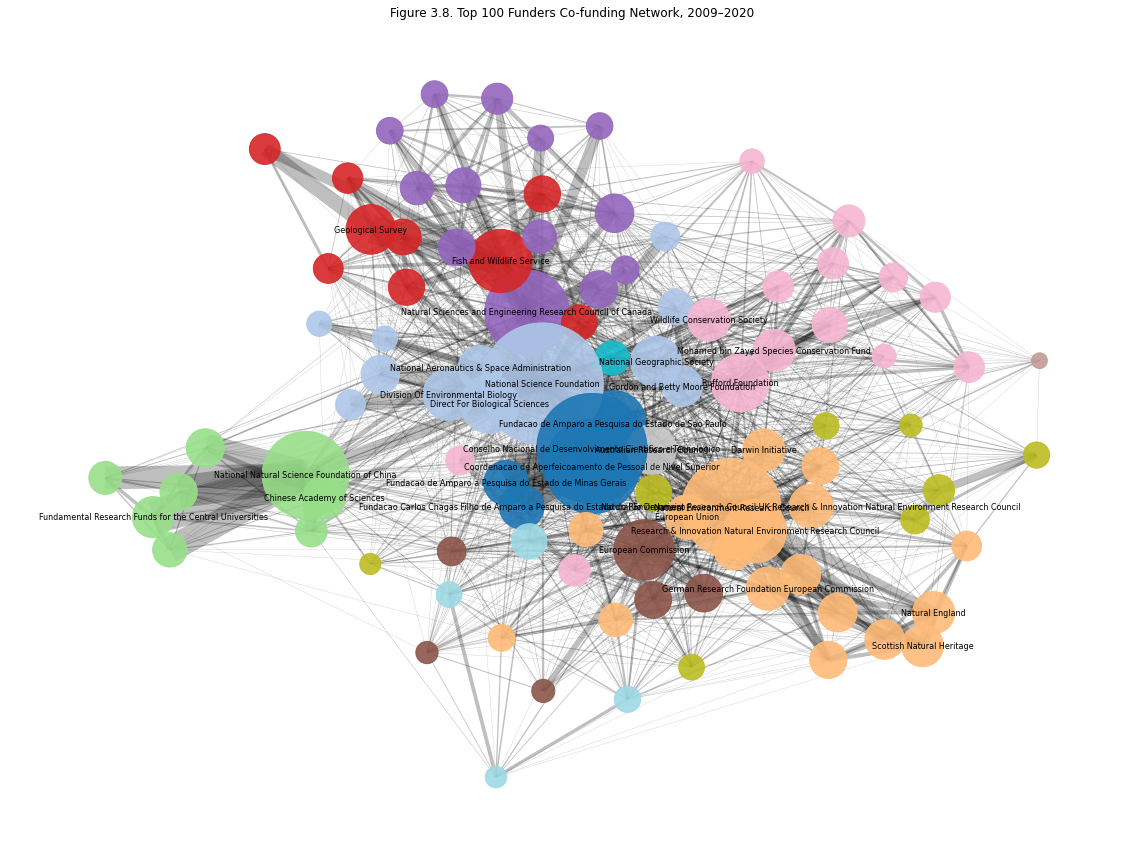

In [25]:
# ============================================================
# Figure 3.8
# Top 100 Funders Co-funding Network
#
# Node size = weighted degree
# Edge width = co-funding frequency
# Node color = Louvain community
# ============================================================

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

# ------------------------------------------------------------
# Select top 100 funders by weighted degree
# ------------------------------------------------------------

top_n = 100

top_funders = (
    centrality_df
    .sort_values("Weighted Degree", ascending=False)
    .head(top_n)
    ["Funder"]
    .tolist()
)

G_top = G.subgraph(top_funders).copy()

print("Top funders network")
print("-------------------")
print("Nodes:", G_top.number_of_nodes())
print("Edges:", G_top.number_of_edges())

# ------------------------------------------------------------
# Node attributes
# ------------------------------------------------------------

weighted_degree_top = dict(
    G_top.degree(weight="weight")
)

degree_top = dict(
    G_top.degree()
)

community_map = dict(
    zip(
        centrality_df["Funder"],
        centrality_df["Community"]
    )
)

node_sizes = [
    weighted_degree_top[n] * 8
    for n in G_top.nodes()
]

node_colors = [
    community_map.get(n, -1)
    for n in G_top.nodes()
]

edge_widths = [
    max(0.3, G_top[u][v]["weight"] * 0.25)
    for u, v in G_top.edges()
]

# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------

pos = nx.spring_layout(
    G_top,
    weight="weight",
    seed=42,
    k=0.45,
    iterations=100
)

# ------------------------------------------------------------
# Draw network
# ------------------------------------------------------------

plt.figure(figsize=(16, 12))

nx.draw_networkx_edges(
    G_top,
    pos,
    width=edge_widths,
    alpha=0.25
)

nx.draw_networkx_nodes(
    G_top,
    pos,
    node_size=node_sizes,
    node_color=node_colors,
    cmap=plt.cm.tab20,
    alpha=0.9
)

# Label top 30 funders by weighted degree
top_label_nodes = (
    pd.Series(weighted_degree_top)
    .sort_values(ascending=False)
    .head(30)
    .index
)

labels = {
    node: node
    for node in top_label_nodes
}

nx.draw_networkx_labels(
    G_top,
    pos,
    labels=labels,
    font_size=8
)

plt.title(
    "Figure 3.8. Top 100 Funders Co-funding Network, 2009–2020"
)

plt.axis("off")
plt.tight_layout()

plt.savefig(
    "Figure_3_8_Top100_Funders_Cofunding_Network_BC.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_3_8_Top100_Funders_Cofunding_Network_BC.pdf",
    bbox_inches="tight"
)

plt.show()

Community network
-----------------
Communities: 705
Between-community edges: 316
Major community network
-----------------------
Communities: 33
Edges: 269


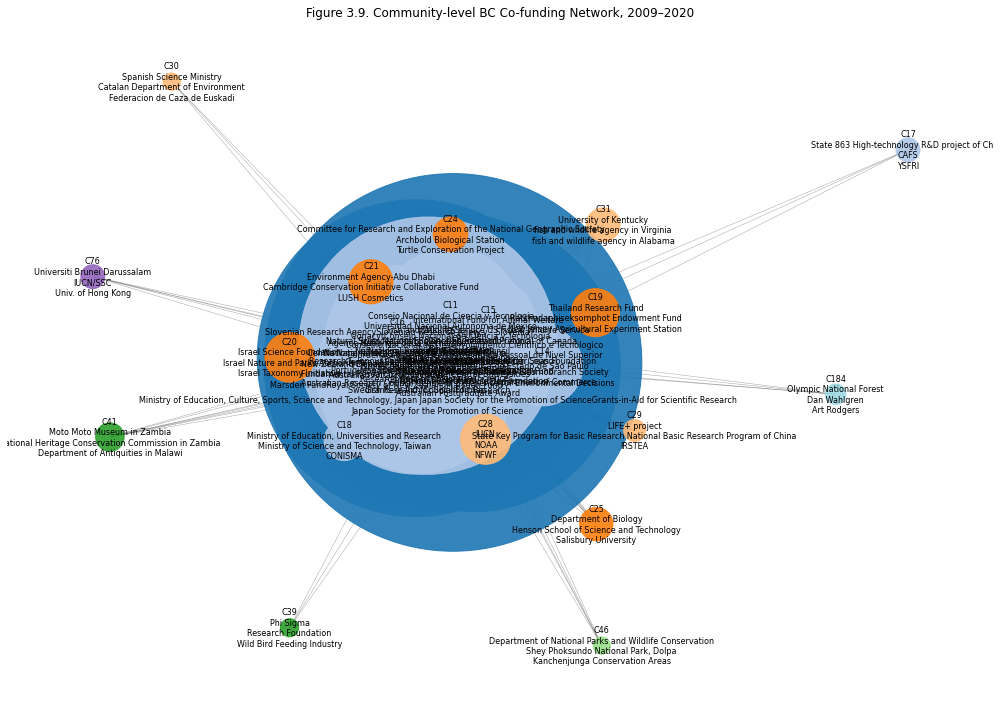

In [26]:
# ============================================================
# Figure 3.9
# Community-level Co-funding Network
#
# Node = Louvain community
# Node size = number of funders in community
# Edge width = total co-funding weight between communities
# ============================================================

import networkx as nx
import matplotlib.pyplot as plt
from collections import defaultdict

# ------------------------------------------------------------
# Community assignment
# ------------------------------------------------------------

community_map = dict(
    zip(
        centrality_df["Funder"],
        centrality_df["Community"]
    )
)

# ------------------------------------------------------------
# Create community-level graph
# ------------------------------------------------------------

G_comm = nx.Graph()

# Add community nodes
community_sizes = (
    centrality_df
    .groupby("Community")
    ["Funder"]
    .count()
    .to_dict()
)

for comm, size in community_sizes.items():
    G_comm.add_node(
        comm,
        size=size
    )

# Add community-level edges
for u, v, data in G.edges(data=True):

    comm_u = community_map.get(u)
    comm_v = community_map.get(v)

    if comm_u is None or comm_v is None:
        continue

    # Skip within-community edges for between-community network
    if comm_u == comm_v:
        continue

    weight = data["weight"]

    if G_comm.has_edge(comm_u, comm_v):
        G_comm[comm_u][comm_v]["weight"] += weight
    else:
        G_comm.add_edge(
            comm_u,
            comm_v,
            weight=weight
        )

print("Community network")
print("-----------------")
print("Communities:", G_comm.number_of_nodes())
print("Between-community edges:", G_comm.number_of_edges())

# ------------------------------------------------------------
# Optional:
# Keep only major communities
# ------------------------------------------------------------

min_community_size = 10

major_communities = [
    comm
    for comm, size in community_sizes.items()
    if size >= min_community_size
]

G_comm_vis = G_comm.subgraph(major_communities).copy()

print("Major community network")
print("-----------------------")
print("Communities:", G_comm_vis.number_of_nodes())
print("Edges:", G_comm_vis.number_of_edges())

# ------------------------------------------------------------
# Node size and edge width
# ------------------------------------------------------------

node_sizes = [
    G_comm_vis.nodes[n]["size"] * 30
    for n in G_comm_vis.nodes()
]

edge_widths = [
    max(0.5, G_comm_vis[u][v]["weight"] * 0.02)
    for u, v in G_comm_vis.edges()
]

# ------------------------------------------------------------
# Labels:
# Community number + top funders
# ------------------------------------------------------------

community_top_funders = {}

for comm in G_comm_vis.nodes():

    top_funders = (
        centrality_df[
            centrality_df["Community"] == comm
        ]
        .sort_values("Weighted Degree", ascending=False)
        ["Funder"]
        .head(3)
        .tolist()
    )

    community_top_funders[comm] = (
        f"C{comm}\n" + "\n".join(top_funders)
    )

# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------

pos = nx.spring_layout(
    G_comm_vis,
    weight="weight",
    seed=42,
    k=1.2,
    iterations=100
)

# ------------------------------------------------------------
# Draw community network
# ------------------------------------------------------------

plt.figure(figsize=(14, 10))

nx.draw_networkx_edges(
    G_comm_vis,
    pos,
    width=edge_widths,
    alpha=0.35
)

nx.draw_networkx_nodes(
    G_comm_vis,
    pos,
    node_size=node_sizes,
    node_color=list(G_comm_vis.nodes()),
    cmap=plt.cm.tab20,
    alpha=0.9
)

nx.draw_networkx_labels(
    G_comm_vis,
    pos,
    labels=community_top_funders,
    font_size=8
)

plt.title(
    "Figure 3.9. Community-level BC Co-funding Network, 2009–2020"
)

plt.axis("off")
plt.tight_layout()

plt.savefig(
    "Figure_3_9_Community_Level_Cofunding_Network_BC.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_3_9_Community_Level_Cofunding_Network_BC.pdf",
    bbox_inches="tight"
)

plt.show()

7. Network Statistics Over Time

In [27]:
# ============================================================
# Table 3.6
# Network Statistics Over Time
#
# Unit of analysis:
# Annual co-funding networks
#
# Node:
# Funding organization
#
# Edge:
# Co-funding relationship between two funders
#
# Edge weight:
# Number of co-funded papers in a given year
# ============================================================

import pandas as pd
import networkx as nx

# ------------------------------------------------------------
# Function:
# Build annual co-funding network from paper-level edge list
# ------------------------------------------------------------

def build_annual_network(edge_df, year):

    # Select edges observed in the given year
    year_edges = edge_df[
        edge_df["Year"] == year
    ].copy()

    # Aggregate repeated co-funding pairs within the year
    annual_weighted_edges = (
        year_edges
        .groupby(["Funder_A", "Funder_B"])
        .size()
        .reset_index(name="Weight")
    )

    # Create graph
    G_year = nx.Graph()

    for _, row in annual_weighted_edges.iterrows():
        G_year.add_edge(
            row["Funder_A"],
            row["Funder_B"],
            weight=row["Weight"]
        )

    return G_year


# ------------------------------------------------------------
# Function:
# Calculate network statistics
# ------------------------------------------------------------

def calculate_network_statistics(G, year):

    nodes = G.number_of_nodes()
    edges = G.number_of_edges()

    # If the network is empty
    if nodes == 0:
        return {
            "Year": year,
            "Nodes": 0,
            "Edges": 0,
            "Density": 0,
            "Components": 0,
            "Largest Component Size": 0,
            "Largest Component Share (%)": 0,
            "Avg Degree": 0,
            "Avg Weighted Degree": 0,
            "Avg Clustering": 0,
            "Avg Weighted Clustering": 0
        }

    # Connected components
    components = list(nx.connected_components(G))

    num_components = len(components)

    largest_component_size = len(
        max(components, key=len)
    )

    largest_component_share = (
        largest_component_size / nodes * 100
    )

    # Average degree
    avg_degree = (
        sum(dict(G.degree()).values()) / nodes
    )

    # Average weighted degree
    avg_weighted_degree = (
        sum(dict(G.degree(weight="weight")).values()) / nodes
    )

    # Density
    density = nx.density(G)

    # Clustering coefficients
    avg_clustering = nx.average_clustering(G)

    avg_weighted_clustering = nx.average_clustering(
        G,
        weight="weight"
    )

    return {
        "Year": year,
        "Nodes": nodes,
        "Edges": edges,
        "Density": density,
        "Components": num_components,
        "Largest Component Size": largest_component_size,
        "Largest Component Share (%)": largest_component_share,
        "Avg Degree": avg_degree,
        "Avg Weighted Degree": avg_weighted_degree,
        "Avg Clustering": avg_clustering,
        "Avg Weighted Clustering": avg_weighted_clustering
    }


# ------------------------------------------------------------
# Create annual network statistics table
# ------------------------------------------------------------

years = sorted(
    paper_edge_list["Year"]
    .dropna()
    .unique()
)

annual_network_stats = []

for year in years:

    G_year = build_annual_network(
        paper_edge_list,
        year
    )

    stats = calculate_network_statistics(
        G_year,
        year
    )

    annual_network_stats.append(stats)

table_3_6_network_stats = pd.DataFrame(
    annual_network_stats
)

# ------------------------------------------------------------
# Round values for dissertation table
# ------------------------------------------------------------

table_3_6_network_stats = table_3_6_network_stats.round({
    "Density": 6,
    "Largest Component Share (%)": 2,
    "Avg Degree": 3,
    "Avg Weighted Degree": 3,
    "Avg Clustering": 3,
    "Avg Weighted Clustering": 4
})

# ------------------------------------------------------------
# Display Table 3.6
# ------------------------------------------------------------

table_3_6_network_stats

,Year,Nodes,Edges,Density,Components,Largest Component Size,Largest Component Share (%),Avg Degree,Avg Weighted Degree,Avg Clustering,Avg Weighted Clustering
0,2009,3444,8543,0.001441,331,2484,72.13,4.961,5.443,0.704,0.0346
1,2010,3781,10726,0.001501,312,2921,77.25,5.674,6.299,0.684,0.0236
2,2011,4072,11726,0.001415,315,3224,79.17,5.759,6.438,0.697,0.0275
3,2012,4676,13941,0.001275,362,3670,78.49,5.963,6.905,0.719,0.0207
4,2013,5256,16261,0.001177,391,4205,80.00,6.188,6.813,0.724,0.0153
5,2014,5491,17525,0.001163,408,4362,79.44,6.383,6.979,0.727,0.0219
6,2015,6208,20444,0.001061,469,4884,78.67,6.586,7.321,0.724,0.0141
7,2016,6359,21456,0.001061,434,5181,81.48,6.748,7.387,0.725,0.0121
8,2017,6647,22872,0.001035,481,5303,79.78,6.882,7.507,0.726,0.0115
9,2018,7547,24804,0.000871,487,6208,82.26,6.573,7.137,0.726,0.0081


In [28]:
table_3_6_network_stats.to_csv(
    "Table_3_6_Network_Statistics_Over_Time_BC.csv",
    index=False
)

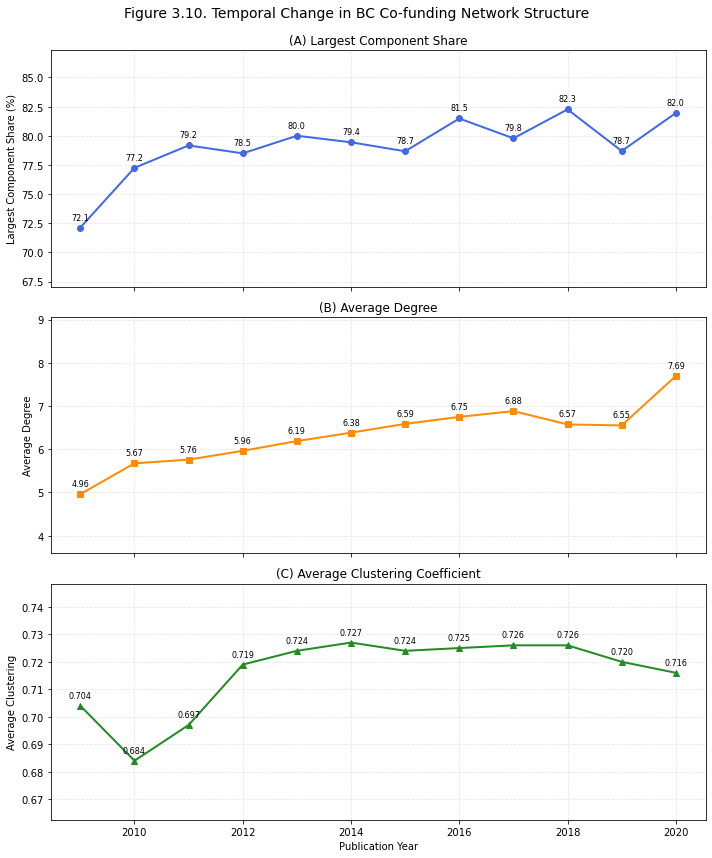

In [29]:
# ============================================================
# Figure 3.10
# Temporal Change in BC Co-funding Network Structure
#
# Panel A: Largest Component Share (%)
# Panel B: Average Degree
# Panel C: Average Clustering Coefficient
#
# Improvements:
# 1. Expanded y-axis range to avoid exaggerated fluctuations
# 2. Value labels added to each point
# 3. Different colors for each metric
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

plot_df = table_3_6_network_stats.copy()

# ------------------------------------------------------------
# Create 3-panel figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(10, 12),
    sharex=True
)

# ============================================================
# Panel A
# Largest Component Share
# ============================================================

y = plot_df["Largest Component Share (%)"]

axes[0].plot(
    plot_df["Year"],
    y,
    marker="o",
    linewidth=2,
    color="royalblue"
)

# Add value labels
for x_val, y_val in zip(plot_df["Year"], y):
    axes[0].annotate(
        f"{y_val:.1f}",
        (x_val, y_val),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=8
    )

# Add padding to y-axis
padding = (y.max() - y.min()) * 0.50

axes[0].set_ylim(
    y.min() - padding,
    y.max() + padding
)

axes[0].set_ylabel(
    "Largest Component Share (%)"
)

axes[0].set_title(
    "(A) Largest Component Share"
)

axes[0].grid(
    alpha=0.3,
    linestyle="--"
)

# ============================================================
# Panel B
# Average Degree
# ============================================================

y = plot_df["Avg Degree"]

axes[1].plot(
    plot_df["Year"],
    y,
    marker="s",
    linewidth=2,
    color="darkorange"
)

for x_val, y_val in zip(plot_df["Year"], y):
    axes[1].annotate(
        f"{y_val:.2f}",
        (x_val, y_val),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=8
    )

padding = (y.max() - y.min()) * 0.50

axes[1].set_ylim(
    y.min() - padding,
    y.max() + padding
)

axes[1].set_ylabel(
    "Average Degree"
)

axes[1].set_title(
    "(B) Average Degree"
)

axes[1].grid(
    alpha=0.3,
    linestyle="--"
)

# ============================================================
# Panel C
# Average Clustering Coefficient
# ============================================================

y = plot_df["Avg Clustering"]

axes[2].plot(
    plot_df["Year"],
    y,
    marker="^",
    linewidth=2,
    color="forestgreen"
)

for x_val, y_val in zip(plot_df["Year"], y):
    axes[2].annotate(
        f"{y_val:.3f}",
        (x_val, y_val),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=8
    )

padding = (y.max() - y.min()) * 0.50

axes[2].set_ylim(
    y.min() - padding,
    y.max() + padding
)

axes[2].set_ylabel(
    "Average Clustering"
)

axes[2].set_xlabel(
    "Publication Year"
)

axes[2].set_title(
    "(C) Average Clustering Coefficient"
)

axes[2].grid(
    alpha=0.3,
    linestyle="--"
)

# ============================================================
# Overall Figure Title
# ============================================================

fig.suptitle(
    "Figure 3.10. Temporal Change in BC Co-funding Network Structure",
    fontsize=14,
    y=0.99
)

plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)

# ============================================================
# Save Figure
# ============================================================

plt.savefig(
    "Figure_3_10_Temporal_Change_BC_Cofunding_Network.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_3_10_Temporal_Change_BC_Cofunding_Network.pdf",
    bbox_inches="tight"
)

plt.show()

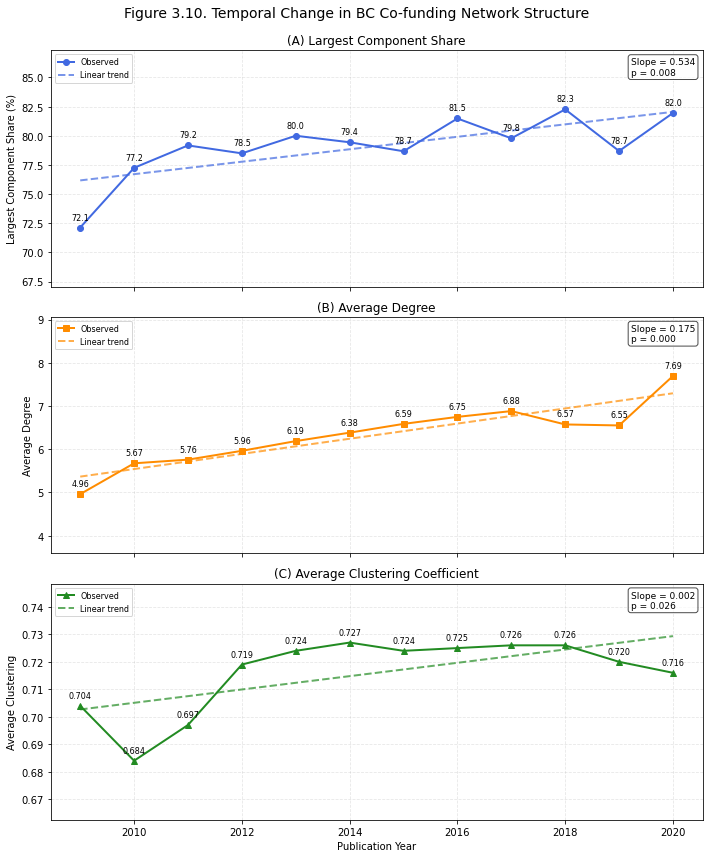

,Metric,Slope,p-value
0,Largest Component Share (%),0.5340,0.0078
1,Average Degree,0.1753,0.0000
2,Average Clustering,0.0024,0.0263


In [30]:
# ============================================================
# Figure 3.10
# Temporal Change in BC Co-funding Network Structure
#
# Panel A: Largest Component Share (%)
# Panel B: Average Degree
# Panel C: Average Clustering Coefficient
#
# Features:
# 1. Expanded y-axis range
# 2. Value labels added to each point
# 3. Different colors for each metric
# 4. Linear trend line added to each panel
# 5. Slope and p-value displayed in each panel
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import linregress

plot_df = table_3_6_network_stats.copy()

# ------------------------------------------------------------
# Helper function for each panel
# ------------------------------------------------------------

def plot_metric_with_trend(
    ax,
    x,
    y,
    color,
    marker,
    title,
    ylabel,
    value_format
):

    # Observed line
    ax.plot(
        x,
        y,
        marker=marker,
        linewidth=2,
        color=color,
        label="Observed"
    )

    # Linear trend
    slope, intercept, r_value, p_value, std_err = linregress(
        x,
        y
    )

    trend = intercept + slope * x

    ax.plot(
        x,
        trend,
        linestyle="--",
        linewidth=2,
        color=color,
        alpha=0.7,
        label="Linear trend"
    )

    # Value labels
    for x_val, y_val in zip(x, y):
        ax.annotate(
            value_format.format(y_val),
            (x_val, y_val),
            textcoords="offset points",
            xytext=(0, 8),
            ha="center",
            fontsize=8
        )

    # Add padding to y-axis
    y_range = y.max() - y.min()

    if y_range == 0:
        padding = y.max() * 0.20
    else:
        padding = y_range * 0.50

    ax.set_ylim(
        y.min() - padding,
        y.max() + padding
    )

    # Add slope and p-value
    ax.text(
        0.89,
        0.97,
        f"Slope = {slope:.3f}\n"
        f"p = {p_value:.3f}",
        transform=ax.transAxes,
        fontsize=9,
        verticalalignment="top",
        bbox=dict(
            boxstyle="round,pad=0.3",
            facecolor="white",
            alpha=0.7
        )
    )

    ax.set_ylabel(ylabel)

    ax.set_title(title)

    ax.grid(
        alpha=0.3,
        linestyle="--"
    )

    ax.legend(
        loc="upper left",
        frameon=True,
        fontsize=8
    )

    return slope, p_value


# ------------------------------------------------------------
# Create 3-panel figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(10, 12),
    sharex=True
)

x = plot_df["Year"].values

# Panel A
slope_lcc, p_lcc = plot_metric_with_trend(
    ax=axes[0],
    x=x,
    y=plot_df["Largest Component Share (%)"].values,
    color="royalblue",
    marker="o",
    title="(A) Largest Component Share",
    ylabel="Largest Component Share (%)",
    value_format="{:.1f}"
)

# Panel B
slope_degree, p_degree = plot_metric_with_trend(
    ax=axes[1],
    x=x,
    y=plot_df["Avg Degree"].values,
    color="darkorange",
    marker="s",
    title="(B) Average Degree",
    ylabel="Average Degree",
    value_format="{:.2f}"
)

# Panel C
slope_clustering, p_clustering = plot_metric_with_trend(
    ax=axes[2],
    x=x,
    y=plot_df["Avg Clustering"].values,
    color="forestgreen",
    marker="^",
    title="(C) Average Clustering Coefficient",
    ylabel="Average Clustering",
    value_format="{:.3f}"
)

axes[2].set_xlabel("Publication Year")

# ------------------------------------------------------------
# Overall title
# ------------------------------------------------------------

fig.suptitle(
    "Figure 3.10. Temporal Change in BC Co-funding Network Structure",
    fontsize=14,
    y=0.99
)

plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)

# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

plt.savefig(
    "Figure_3_10_Temporal_Change_BC_Cofunding_Network_with_Trends.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_3_10_Temporal_Change_BC_Cofunding_Network_with_Trends.pdf",
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# Optional: Create trend summary table
# ------------------------------------------------------------

figure_3_10_trend_summary = pd.DataFrame({
    "Metric": [
        "Largest Component Share (%)",
        "Average Degree",
        "Average Clustering"
    ],
    "Slope": [
        slope_lcc,
        slope_degree,
        slope_clustering
    ],
    "p-value": [
        p_lcc,
        p_degree,
        p_clustering
    ]
})

figure_3_10_trend_summary = figure_3_10_trend_summary.round(4)

figure_3_10_trend_summary